In [39]:
#!pip install scikit-fuzzy

In [78]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np


###  **Variables de entrada (Antecedentes)**
#### Compromiso (CO)
#### Comunicación (CM)
#### Feedback y evaluación (FE)
#### Habilidades de enseñanza (HE)

In [79]:
CO = ctrl.Antecedent(np.arange(0, 6, 1), 'Compromiso')
CM = ctrl.Antecedent(np.arange(0, 6, 1), 'Comunicación')
FE = ctrl.Antecedent(np.arange(0, 6, 1), 'Feedback y Evaluación')
HE = ctrl.Antecedent(np.arange(0, 6, 1), 'Habilidades de Enseñanza')

### **Variables de salida (Consecuentes)**

#### Evaluación de desempeño (ED)

In [80]:
ED = ctrl.Consequent(np.arange(0, 6, 1),'Evaluación de desempeño')

### **Conjuntos difusos**

In [81]:
# Compromiso
CO['bajo'] = fuzz.trimf(CO.universe, [0, 1, 2])
CO['medio'] = fuzz.trapmf(CO.universe, [1, 2, 3, 4])
CO['alto'] = fuzz.trapmf(CO.universe, [3, 4, 5, 5])

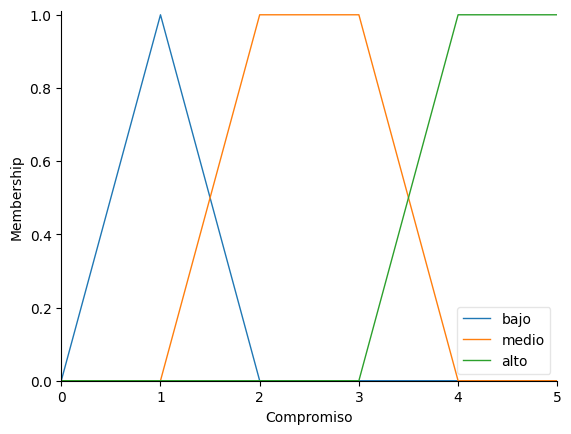

In [82]:
CO.view()

In [83]:
# Comunicación
CM['bajo'] = fuzz.trimf(CM.universe, [0, 1, 2])
CM['medio'] = fuzz.trapmf(CM.universe, [1, 2, 3, 4])
CM['alto'] = fuzz.trapmf(CM.universe, [3, 4, 5, 5])

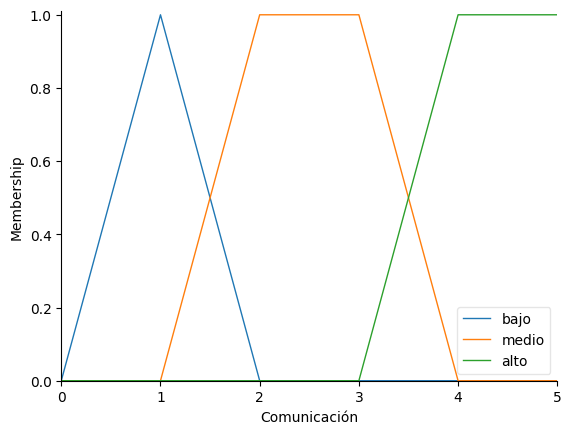

In [84]:
CM.view()

In [85]:
# Feedback y Evaluación
FE['bajo'] = fuzz.trimf(FE.universe, [0, 1, 2])
FE['medio'] = fuzz.trapmf(FE.universe, [1, 2, 3, 4])
FE['alto'] = fuzz.trapmf(FE.universe, [3, 4, 5, 5])

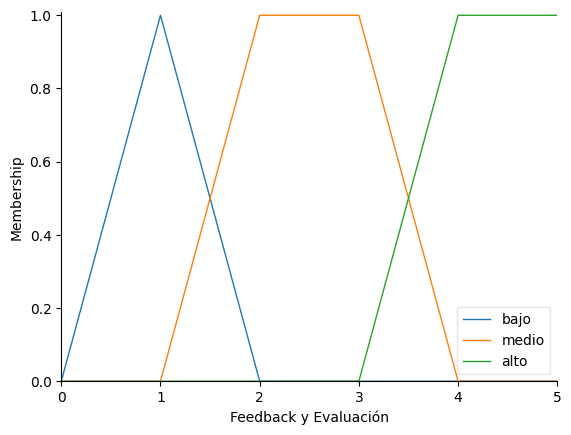

In [86]:
FE.view()

In [87]:
HE['bajo'] = fuzz.trimf(HE.universe, [0, 1, 2])
HE['medio'] = fuzz.trapmf(HE.universe, [1, 2, 3, 4])
HE['alto'] = fuzz.trapmf(HE.universe, [3, 4, 5, 5])

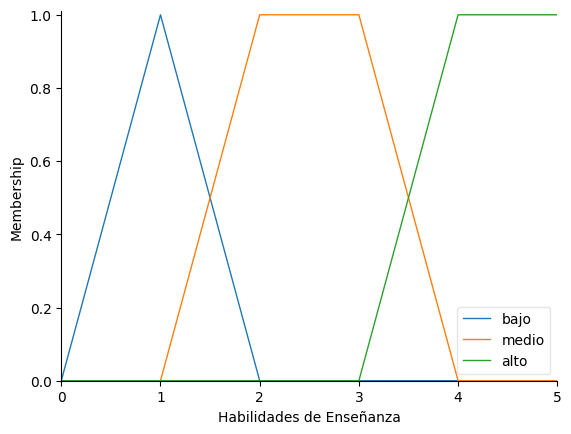

In [88]:
HE.view()

In [89]:
ED['bajo'] = fuzz.trimf(ED.universe, [0, 1, 2])
ED['medio'] = fuzz.trapmf(ED.universe, [1, 2, 3, 4])
ED['alto'] = fuzz.trapmf(ED.universe, [3, 4, 5, 5])

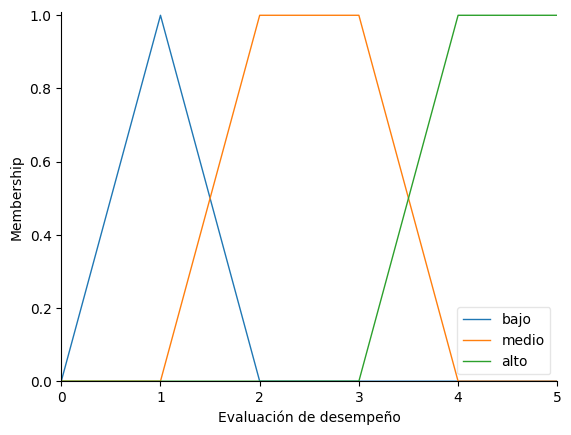

In [90]:
ED.view()

## Crear reglas

In [91]:
rule1 = ctrl.Rule(CO['bajo'] | CM['bajo'] | FE['bajo'] | HE['bajo'], ED['bajo'])
rule2 = ctrl.Rule(CO['medio'] & CM['medio'] & FE['medio'] & HE['medio'], ED['medio'])
rule3 = ctrl.Rule(CO['alto'] & CM['alto'] & FE['alto'] & HE['alto'], ED['alto'])
rule4 = ctrl.Rule((CO['alto'] | CM['alto']) & (FE['medio'] | HE['medio']), ED['medio'])
rule5 = ctrl.Rule((CO['medio'] & CM['medio']) | (FE['alto'] & HE['alto']), ED['alto'])

In [92]:
# Sistema de control y la simulación
desempeño_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5])
desempeño_sim = ctrl.ControlSystemSimulation(desempeño_ctrl)

In [111]:
# Asignando algunas entradas para probar el sistema
desempeño_sim.input['Compromiso'] = 1
desempeño_sim.input['Comunicación'] = 1
desempeño_sim.input['Feedback y Evaluación'] = 1
desempeño_sim.input['Habilidades de Enseñanza'] = 1


In [112]:
# Computando el resultado
desempeño_sim.compute()

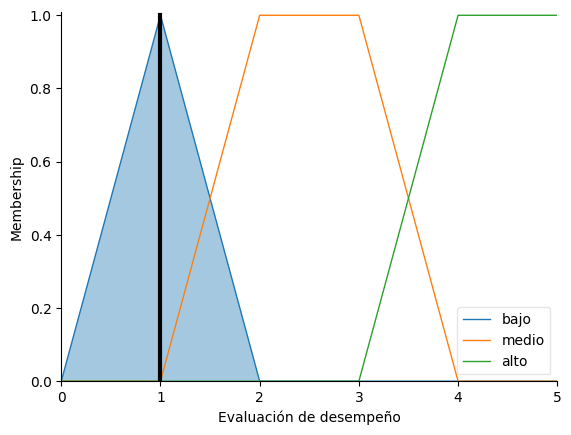

In [113]:
# Imprimiendo el nivel de desempeño resultante
output_desempeño = desempeño_sim.output['Evaluación de desempeño']
output_desempeño
ED.view(sim=desempeño_sim)